# NB1b · Rule engine v1 — votes, diagnostics, key events

Runs `src/rules_v1.py`. It adds **R3, R4, R5, R6, R11, R12, R15** from the guide and a new **linear-interpolation family R19–R21**.
Every rule votes for one type or abstains. Conflicts are expected; the label model (NB2) resolves them.

| Rule | Votes | Item | Condition (v1) |
|---|---|---|---|
| R3 hold → zero | A1 | dead | a hold run in the same zone ends exactly when the dead run starts |
| R4 mixed hold/dead | A1 | dead | other zones hold **co-extensively** with the dead event (time IoU ≥ 0.5) |
| R5 cold-load pickup | G | dead | overshoot π ≥ 1.15 |
| R6 noise floor | G | dead | exact-zero share η < 0.9 |
| R11 long single zone | G3 | dead | one zone, duration > 24 h |
| R12 single-zone stuck | A3 | fill | one zone holds ≥ 6 points (≥ 12 for Marrakech) while ≥ 80 % of neighbour zone-steps move |
| R15 profile shift | A4 | clock | \|δ*\| ≥ 50 min **and** corr after shift ≥ 0.9 **and** gain over no shift ≥ 0.05 (v1 fit-quality guard) |
| **R19** multi-zone linear fill | A2 | fill | ≥ 2 zones linearly interpolated, starting within 10 min |
| **R20** single-zone linear fill | A3 | fill | one zone interpolated while its neighbours move |
| **R21** linear fill + dead | A1 | dead | interpolation co-extensive with the dead event in other zones, or ending where it starts |

**Changes from the guide:**
- R7 also abstains when R21 fires, because linear fill is fill evidence just like a hold.
- Dead runs no longer need an exact zero: noise-floor-only runs are the G3 signature (H1).
- Non-zero points lying on a straight line count as interpolation, not as a noise floor.
- Marrakech uses 12-point minimums because its values are whole kW.
- **Restoration (r, π, τ) is measured after any straight-line ramp that directly follows a dead run.** About 1 in 5 southern dead runs (25 of 117), including C02, C04 and C07, "restore" through a linear fill. Measuring there would make H2's ramp evidence an interpolation artefact. The `fill_ramp_zones` and `fill_ramp_min` columns record it.

Outputs: `results/catalogue_v1/{items,votes,zone_runs,rule_summary}.csv` and figures in `results/figures/`.

In [1]:
import sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/grid-event-or-data-artefact")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
try:
    import openpyxl  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openpyxl"], check=True)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import Patch
import rules_v1 as R1, rules_v0 as R0, viz
from viz import COL, LABEL_COL, savefig

XLSX = ROOT / "data" / "raw" / "Data Morocco.xlsx"
OUT = ROOT / "results" / "catalogue_v1"; OUT.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)
print("ROOT =", ROOT)

ROOT = C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact


## Run rule engine v1

In [2]:
res = R1.build(XLSX)
items, votes, zr, summary = res["items"], res["votes"], res["zone_runs"], res["rule_summary"]
data, exp, masks = res["data"], res["exp"], res["masks"]
for k in ("items", "votes", "zone_runs", "rule_summary"):
    res[k].to_csv(OUT / f"{k}.csv", index=False)
V = votes.set_index("item_id")
print(items.groupby("kind").size().to_string())
print("\nzone runs:", zr.groupby(["system", "kind"]).size().to_dict())

kind
clock        33
dead        126
fill        155
transfer     13

zone runs: {('Marrakech', 'dead'): 48, ('Marrakech', 'hold'): 7, ('south', 'dead'): 117, ('south', 'hold'): 95, ('south', 'interp'): 274}


## Overview: inspection label per item kind
`mv_label` is a majority vote, for inspection only. NB2's label model replaces it.
`conflict:G3|G4` is expected by design: R9 (any single zone → G3) and R10 (single zone inside the maintenance window → G4) both fire.
The label model learns that R9 cannot separate G3 from G4 and leaves that decision to R10.

In [3]:
print(pd.crosstab(items.mv_label, items.kind, margins=True).to_string())
summary

kind               clock  dead  fill  transfer  All
mv_label                                           
A1                     0     2     0         0    2
A2                     0     0    57         0   57
A3                     0     0    92         0   92
A4                    15     0     0         0   15
G2                     0     1     0         0    1
G3                     0    53     0         0   53
G5                     0     0     0         1    1
abstain               18     0     6        12   36
conflict:A1|G3|G4      0     2     0         0    2
conflict:A1|G?         0     1     0         0    1
conflict:G3|G4         0    67     0         0   67
All                   33   126   155        13  327


,rule,family,item_kind,n_items_of_kind,n_votes,coverage,labels,overlap,conflict
0,R1,simultaneity,dead,126,1,0.008,A1,1,0
1,R2,hold,fill,155,12,0.077,A2,3,0
2,R3,hold,dead,126,3,0.024,A1,2,1
3,R4,hold,dead,126,3,0.024,A1,3,2
4,R5,restoration,dead,126,21,0.167,G,21,2
5,R6,restoration,dead,126,84,0.667,G,84,5
6,R7,simultaneity,dead,126,0,0.000,,0,0
7,R8,city,dead,126,1,0.008,G2,0,0
8,R9,single_zone,dead,126,122,0.968,G3,116,71
9,R10,calendar,dead,126,69,0.548,G4,69,69


## Fig. 7 — Rule coverage, overlap and conflict

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/fig7_rule_diagnostics.png


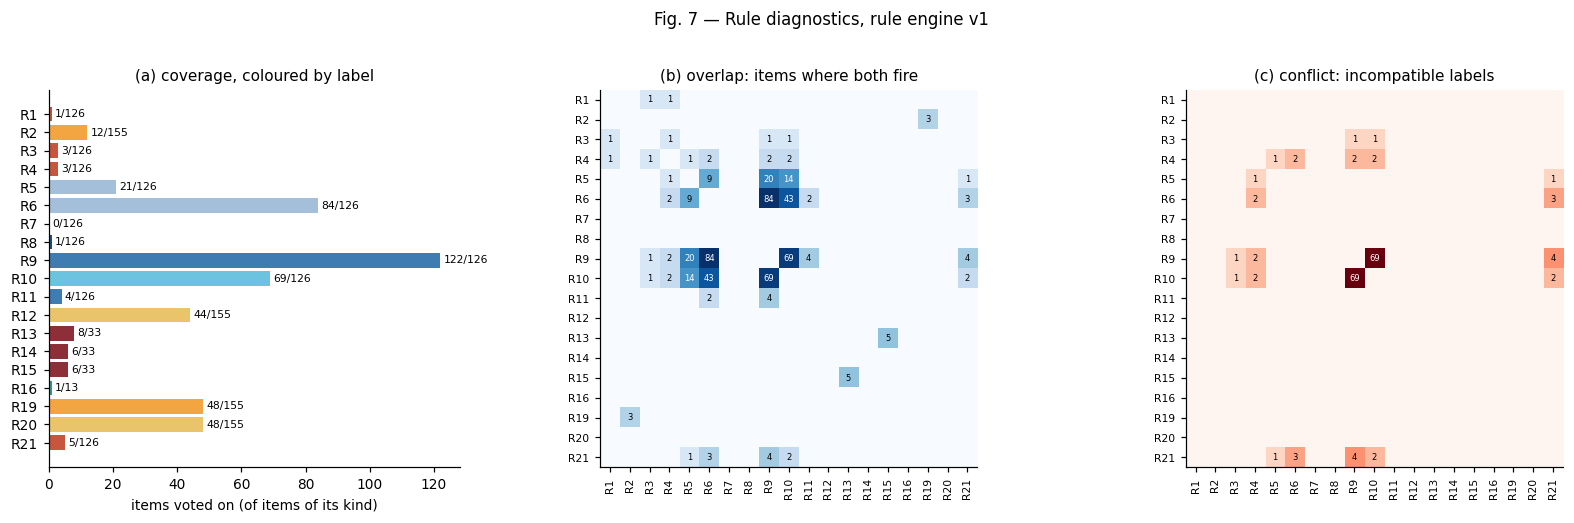

In [4]:
rules = R1.RULES
fired = V.notna()
ov = pd.DataFrame(0, index=rules, columns=rules); cf = ov.copy()
for i in V.index:
    f = [r for r in rules if fired.at[i, r]]
    for a in f:
        for b in f:
            if a == b: continue
            ov.at[a, b] += 1
            cf.at[a, b] += int(not R1.compatible(V.at[i, a], V.at[i, b]))
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[1, 1.25, 1.25]))
cov = summary.set_index("rule")
cols = [LABEL_COL.get(l.split(",")[0], "#ccc") if l else "#ccc" for l in cov.labels]
axs[0].barh(cov.index[::-1], cov.n_votes[::-1], color=cols[::-1])
for y, (n, k) in enumerate(zip(cov.n_votes[::-1], cov.n_items_of_kind[::-1])):
    axs[0].text(n + 1, y, f"{n}/{k}", va="center", fontsize=7)
axs[0].set_xlabel("items voted on (of items of its kind)"); axs[0].set_title("(a) coverage, coloured by label")
for ax, M_, t, cmap in [(axs[1], ov, "(b) overlap: items where both fire", "Blues"), (axs[2], cf, "(c) conflict: incompatible labels", "Reds")]:
    m = np.log1p(M_.values)
    ax.imshow(m, cmap=cmap)
    ax.set_xticks(range(len(rules))); ax.set_xticklabels(rules, rotation=90, fontsize=7)
    ax.set_yticks(range(len(rules))); ax.set_yticklabels(rules, fontsize=7)
    for (a, b), val in np.ndenumerate(M_.values):
        if val: ax.text(b, a, str(val), ha="center", va="center", fontsize=5.5, color="white" if m[a, b] > m.max() * .6 else "black")
    ax.set_title(t)
fig.suptitle("Fig. 7 — Rule diagnostics, rule engine v1", y=1.02); fig.tight_layout()
savefig(fig, FIG, "fig7_rule_diagnostics"); plt.show()

## Key events from the guide's catalogue → v1 items and episodes
An **episode** links dead and fill items that share boundaries, for example a hold that turns into a zero fill.

In [5]:
KEY = [("C01", "2022-10-23 08:00", "2022-10-24 10:00", "L5"), ("C02", "2022-10-29 20:40", "2022-11-03 09:00", "F4"),
       ("C04", "2022-11-16 22:40", "2022-11-17 09:00", "F1"), ("C05/C06", "2023-01-26 01:00", "2023-01-29 11:00", None),
       ("C07", "2023-02-10 08:20", "2023-02-12 04:00", "F6"), ("C09", "2023-07-16 14:00", "2023-07-17 08:00", None),
       ("C12", "2024-03-31 09:00", "2024-04-02 08:00", None), ("G2 cand.", "2022-09-26 08:00", "2022-09-26 10:00", None)]
rows = []
for cid, a, b, zone in KEY:
    m = items[items.kind.isin(["dead", "fill"]) & (items.start >= a) & (items.start <= b)]
    if zone: m = m[m.zones.str.contains(zone)]
    for r in m.itertuples():
        rows.append(dict(guide_id=cid, item=r.item_id, episode=r.episode, kind=r.kind, start=r.start, h=r.duration_h,
                         zones=r.zones if len(r.zones) < 40 else f"{r.n_zones} zones ({r.cities})", votes=r.votes, mv=r.mv_label))
key_tab = pd.DataFrame(rows); key_tab.to_csv(OUT / "key_events_v1.csv", index=False)
print(key_tab.to_string(index=False))
print()
print(items[items.kind.isin(["clock", "transfer"]) & (items.n_votes > 0)][["item_id", "kind", "start", "cities", "zones", "votes"]].to_string(index=False))

guide_id item episode kind               start      h                                    zones              votes                mv
     C01 D052   EP020 dead 2022-10-23 08:10:00   1.50                                       L5  R6:G;R9:G3;R10:G4    conflict:G3|G4
     C01 D053   EP020 dead 2022-10-23 18:30:00  15.00                                       L5  R6:G;R9:G3;R21:A1                G3
     C01 F025   EP020 fill 2022-10-23 09:40:00   1.50                                       L5             R20:A3                A3
     C01 F026   EP020 fill 2022-10-23 11:20:00   7.17                                       L5             R20:A3                A3
     C02 D058   EP028 dead 2022-10-29 20:40:00 108.17                                       F4       R9:G3;R11:G3                G3
     C02 F033   EP028 fill 2022-11-03 08:50:00   1.67                                       F4             R20:A3                A3
     C04 D064   EP033 dead 2022-11-16 22:40:00  10.17                       

## v0 → v1: what happened to the 72 v0 dead events?
For each v0 event: is there a v1 dead item with the same start? Otherwise, which v1 items cover that start?

In [6]:
v0 = pd.read_csv(ROOT / "results" / "event_catalogue_v0" / "zero_events.csv", parse_dates=["start", "end"])
dead = items[items.kind == "dead"]
status = []
for r in v0.itertuples():
    same = dead[dead.start == r.start]
    if len(same):
        status.append(dict(v0_event=r.event, start=r.start, v0_type=r.provisional_type, outcome="same start", v1=",".join(same.item_id), v1_mv=",".join(same.mv_label)))
    else:
        cover = items[items.kind.isin(["dead", "fill"]) & (items.start <= r.end) & (items.end >= r.start)]
        status.append(dict(v0_event=r.event, start=r.start, v0_type=r.provisional_type, outcome="re-segmented",
                           v1=",".join(cover.item_id), v1_mv=",".join(cover.mv_label)))
cmp = pd.DataFrame(status)
print(cmp.outcome.value_counts().to_string())
print(cmp[cmp.outcome != "same start"].to_string(index=False))
new = dead[~dead.start.isin(v0.start)]
print(f"\nv1 dead items not in v0: {len(new)} ->", new.groupby("cities").size().to_dict())

outcome
same start      70
re-segmented     2
 v0_event               start          v0_type      outcome             v1    v1_mv
        5 2022-10-23 11:10:00 G3_feeder_outage re-segmented D053,F025,F026 G3,A3,A3
       53 2023-10-21 11:50:00 G4_planned_work? re-segmented      D017,F110    G3,A3

v1 dead items not in v0: 56 -> {'Boujdour': 3, 'Foum eloued': 6, 'Laayoune': 4, 'Marrakech': 43}


## E10 — C01 re-read: zeros, then a straight-line fill, then zeros
v0 called C01 a 22 h noise-floor outage (η = 0.51). In v1 the low "noise floor" between the two zero spells is a perfect straight line, which a de-energised feeder cannot produce.

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/E10_C01_relabelled.png


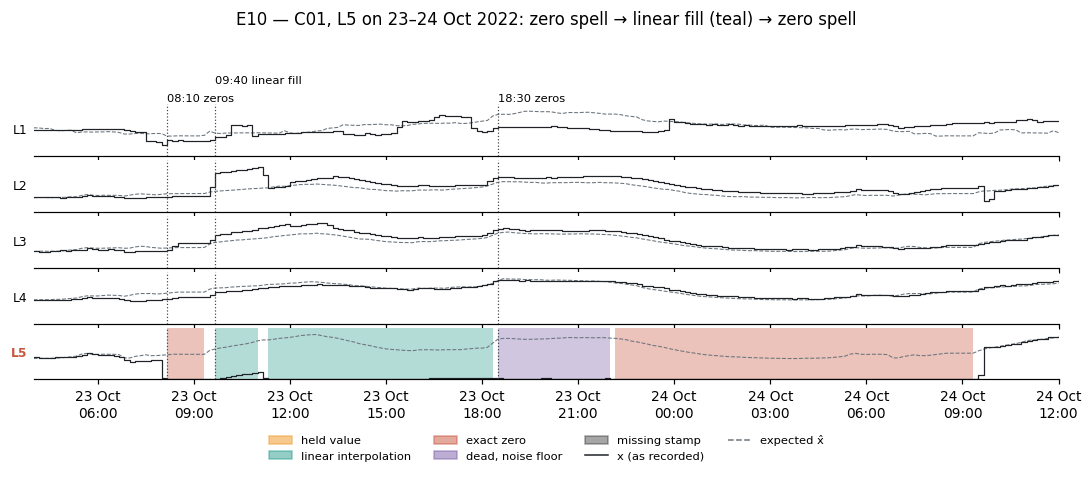

system     city  zone code   kind               start                 end  steps  n_zero  value  slope  quantised
 south Laayoune zone5   L5   dead 2022-10-23 08:10:00 2022-10-23 09:40:00      9       8    NaN    NaN      False
 south Laayoune zone5   L5   dead 2022-10-23 18:30:00 2022-10-24 09:30:00     90      68    NaN    NaN      False
 south Laayoune zone5   L5 interp 2022-10-23 09:40:00 2022-10-23 11:10:00      9       0    NaN 3.0115      False
 south Laayoune zone5   L5 interp 2022-10-23 11:20:00 2022-10-23 18:30:00     43       0    NaN 0.1117      False


In [7]:
fig, axes = viz.stack_plot(data, exp, masks, "2022-10-23 04:00", "2022-10-24 12:00", viz.zone_list(data, ["Laayoune"]),
    title="E10 — C01, L5 on 23–24 Oct 2022: zero spell → linear fill (teal) → zero spell",
    marks=[("2022-10-23 08:10", "08:10 zeros"), ("2022-10-23 09:40", "09:40 linear fill"), ("2022-10-23 18:30", "18:30 zeros")],
    highlight=[("Laayoune", "zone5")])
savefig(fig, FIG, "E10_C01_relabelled"); plt.show()
print(zr[(zr.code == "L5") & (zr.start >= "2022-10-23") & (zr.start < "2022-10-24 12:00")].to_string(index=False))

## E11 — Short simultaneous freezes (3–5 points) per week
Found while setting thresholds: Laâyoune has about 1,070 freezes of 3–5 identical points, mostly in **all 5 zones at once**, until Apr 2023.
They sit below the 6-point hold threshold, so v1 doesn't vote on them. Lowering the threshold for multi-zone holds is part of the sensitivity sweep (ablation 6).

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/E11_short_simultaneous_freezes.png


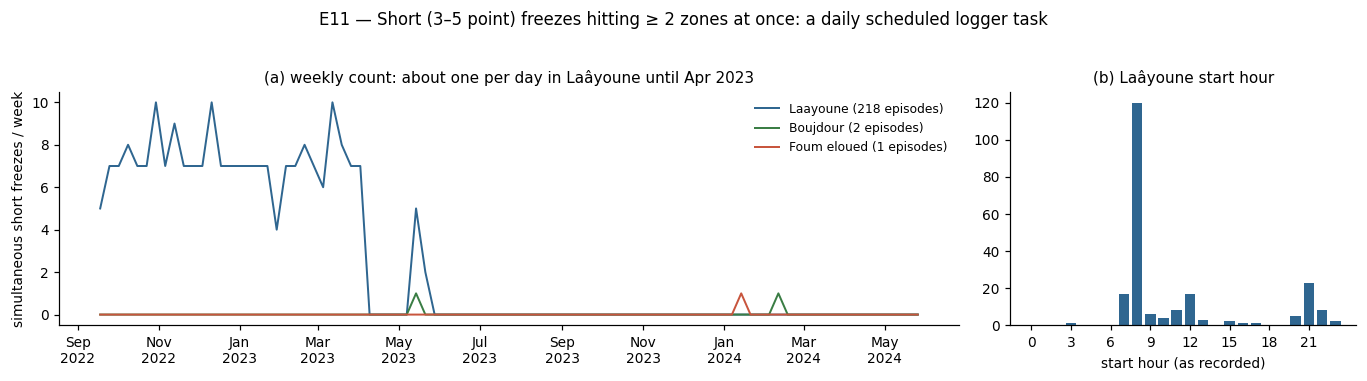

Laâyoune: 218 episodes, 120 start in the 08:00 hour, 186 days with exactly one


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.3), gridspec_kw=dict(width_ratios=[2.6, 1]))
starts_L = None
for c, col in zip(R0.SOUTH, ["#2F6690", "#3A7D44", "#C8553D"]):
    d = data[c]
    short = d.apply(lambda s: R1.hold_mask(s, 3)) & ~d.apply(lambda s: R1.hold_mask(s, 6))
    sim = short.sum(axis=1) >= 2                                   # >= 2 zones in a short freeze at the same step
    starts = sim & ~sim.shift(1, fill_value=False)
    if c == "Laayoune": starts_L = starts[starts].index
    wk = starts.resample("W").sum()
    axs[0].plot(wk.index, wk.values, color=col, lw=1.3, label=f"{c} ({int(starts.sum())} episodes)")
axs[0].set_ylabel("simultaneous short freezes / week"); axs[0].legend(fontsize=8)
axs[0].set_title("(a) weekly count: about one per day in Laâyoune until Apr 2023")
axs[0].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axs[1].bar(range(24), pd.Series(starts_L.hour).value_counts().reindex(range(24), fill_value=0), color="#2F6690")
axs[1].set_xlabel("start hour (as recorded)"); axs[1].set_xticks(range(0, 24, 3)); axs[1].set_title("(b) Laâyoune start hour")
per_day = pd.Series(1, index=starts_L).resample("D").sum()
fig.suptitle("E11 — Short (3–5 point) freezes hitting ≥ 2 zones at once: a daily scheduled logger task", y=1.03)
fig.tight_layout(); savefig(fig, FIG, "E11_short_simultaneous_freezes"); plt.show()
print(f"Laâyoune: {len(starts_L)} episodes, {int((starts_L.hour == 8).sum())} start in the 08:00 hour, {int((per_day == 1).sum())} days with exactly one")

## E9 — Vote matrix for the informative items (multi-zone dead/fill, clock and transfer items with votes)

saved C:\Users\Dell\Desktop\phd_ehtp\energy paper\anomaly_detection\Grid event or data artefact\results\figures/E9_vote_matrix.png


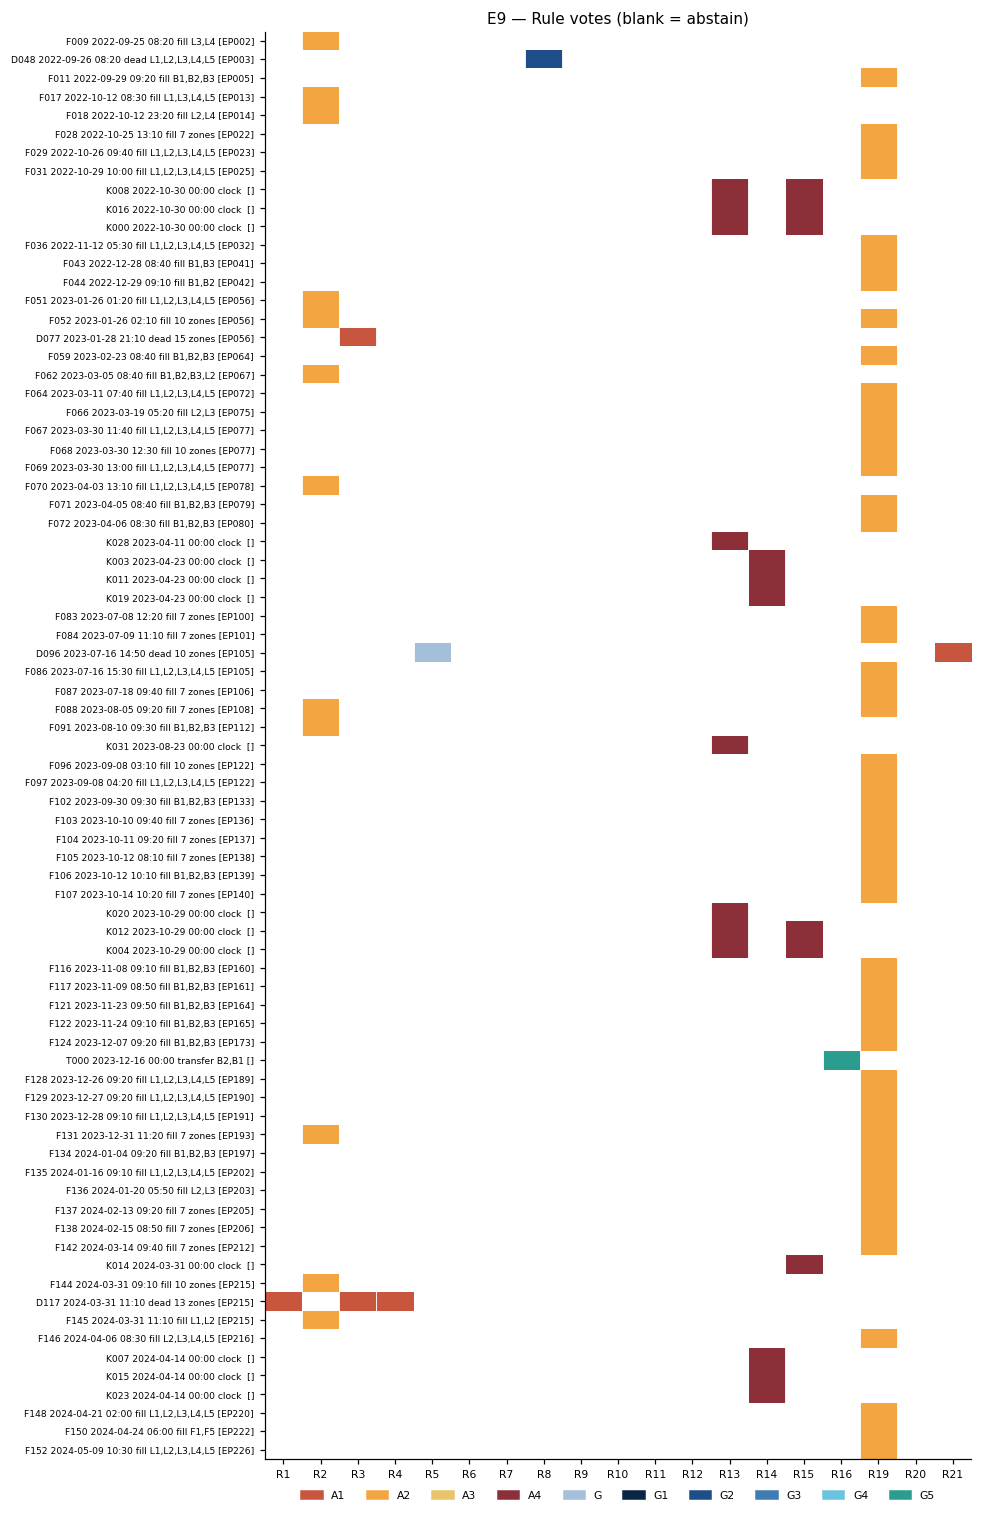

In [9]:
sel = items[((items.kind.isin(["dead", "fill"])) & (items.n_zones >= 2)) | ((items.kind.isin(["clock", "transfer"])) & (items.n_votes > 0))]
sel = sel.sort_values("start")
labs = sorted(LABEL_COL)
codes = V.loc[sel.item_id].apply(lambda col: col.map({l: i for i, l in enumerate(labs)}))
from matplotlib.colors import ListedColormap
cmap = ListedColormap([LABEL_COL[l] for l in labs])
fig, ax = plt.subplots(figsize=(9, 0.16 * len(sel) + 1.5))
ax.imshow(codes.values.astype(float), aspect="auto", cmap=cmap, vmin=-.5, vmax=len(labs) - .5, interpolation="nearest")
ax.set_xticks(range(len(R1.RULES))); ax.set_xticklabels(R1.RULES, fontsize=7)
ax.set_yticks(range(len(sel)))
ax.set_yticklabels([f"{r.item_id} {r.start:%Y-%m-%d %H:%M} {r.kind} {r.zones if len(str(r.zones)) < 18 else str(r.n_zones) + ' zones'} [{r.episode if isinstance(r.episode, str) else ''}]"
                    for r in sel.itertuples()], fontsize=6)
ax.set_xticks(np.arange(-.5, len(R1.RULES)), minor=True); ax.grid(which="minor", color="white", lw=.6); ax.tick_params(which="minor", length=0)
ax.legend(handles=[Patch(color=LABEL_COL[l], label=l) for l in labs], ncol=10, fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.03 * 40 / max(len(sel), 40)))
ax.set_title("E9 — Rule votes (blank = abstain)")
fig.tight_layout(); savefig(fig, FIG, "E9_vote_matrix"); plt.show()

## Compound episodes (≥ 2 items)

In [10]:
ep = (items[items.episode.notna()].groupby("episode")
      .agg(start=("start", "min"), end=("end", "max"), n_items=("item_id", "size"), items=("item_id", ",".join),
           kinds=("kind", lambda k: "+".join(sorted(set(k)))), labels=("mv_label", lambda l: ",".join(l)), cities=("cities", lambda c: "+".join(sorted(set("+".join(c).split("+")))))))
ep = ep[ep.n_items >= 2].sort_values("start")
ep.to_csv(OUT / "episodes_compound.csv")
print(len(ep), "compound episodes"); ep

38 compound episodes


,start,end,n_items,items,kinds,labels,cities
episode,,,,,,,
EP007,2022-10-01 09:00:00,2022-10-01 11:40:00,2,"D049,F013",dead+fill,"conflict:G3|G4,A3",Foum eloued
EP018,2022-10-19 11:40:00,2022-10-19 18:20:00,2,"F022,F023",fill,"A3,A3",Laayoune
EP020,2022-10-23 08:10:00,2022-10-24 09:30:00,4,"D052,D053,F025,F026",dead+fill,"conflict:G3|G4,G3,A3,A3",Laayoune
EP021,2022-10-25 08:10:00,2022-10-25 12:40:00,2,"D054,F027",dead+fill,"conflict:G3|G4,A3",Foum eloued
EP023,2022-10-26 08:10:00,2022-10-26 11:00:00,2,"D055,F029",dead+fill,"conflict:G3|G4,A2",Laayoune
EP025,2022-10-29 10:00:00,2022-10-29 14:10:00,2,"D056,F031",dead+fill,"G3,A2",Boujdour+Laayoune
EP028,2022-10-29 20:40:00,2022-11-03 10:30:00,2,"D058,F033",dead+fill,"G3,A3",Foum eloued
EP027,2022-10-30 06:00:00,2022-10-30 17:50:00,2,"D059,F032",dead+fill,"conflict:G3|G4,A3",Boujdour
EP029,2022-11-05 07:20:00,2022-11-05 11:10:00,4,"D060,D061,F034,F035",dead+fill,"conflict:G3|G4,conflict:G3|G4,abstain,A3",Foum eloued+Laayoune
